# Практическая работа № 9. Метод опорных векторов (Уровень B)

**Цель работы:** исследовать влияние ядровой функции и гиперпараметров `C` и `gamma` на поведение классификатора SVM, визуализировать границы решения и провести корректное сравнение с моделями из ПР-7 и ПР-8 на едином разбиении данных.

**Выполненные требования уровня B и общие требования к сдаче:**
1. Обязательное масштабирование признаков (`StandardScaler`) внутри `Pipeline`, исключающее утечку данных при кросс-валидации.
2. Визуализация границ решения для линейного ядра и ядра RBF на двумерных данных с демонстрацией влияния гиперпараметров `C` и `gamma` (включая эффект переобучения при слишком большом `gamma`).
3. Сеточный поиск (`GridSearchCV`) по параметрам `C` и `gamma` для ядра RBF на основном рабочем датасете.
4. Построение тепловой карты (heatmap) качества по сетке параметров и анализ наблюдаемой закономерности.
5. Сравнение лучшей модели `SVC (RBF)` с `SVC (Linear)` и моделями из ПР-7 (`RandomForest`) и ПР-8 (`HistGradientBoosting` / бустинг) по метрикам и времени обучения.
6. Формулировка обоснованного вывода о целесообразности применения SVM на этих данных с учётом вычислительных затрат.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.datasets import load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Единое зерно генератора случайных чисел для воспроизводимости (как в ПР-7 и ПР-8)
RANDOM_STATE = 42

print(f"NumPy version:        {np.__version__}")
print(f"Scikit-learn version: {sklearn.__version__}")

NumPy version:        2.5.4
Scikit-learn version: 1.9.1


## 1. Визуализация границ решения и влияния гиперпараметров `C` и `gamma`

Перед настройкой модели на многомерном основном датасете наглядно посмотрим, как работают линейное и RBF-ядра, а также как гиперпараметры `C` и `gamma` меняют форму разделяющей границы на двумерных нелинейных данных (`make_moons`):
* **Ядро `linear`** строит прямую разделяющую гиперплоскость — она не способна разделить нелинейно переплетённые классы.
* **Ядро `rbf`** (радиально-базисная функция) проецирует данные в пространство более высокой размерности и строит плавную нелинейную границу.
* **Параметр `C`** управляет штрафом за ошибки на обучении (жёсткость зазора).
* **Параметр `gamma`** определяет радиус влияния каждого опорного вектора: при слишком большом `gamma` граница начинает «обволакивать» отдельные точки обучающей выборки (классическое переобучение).

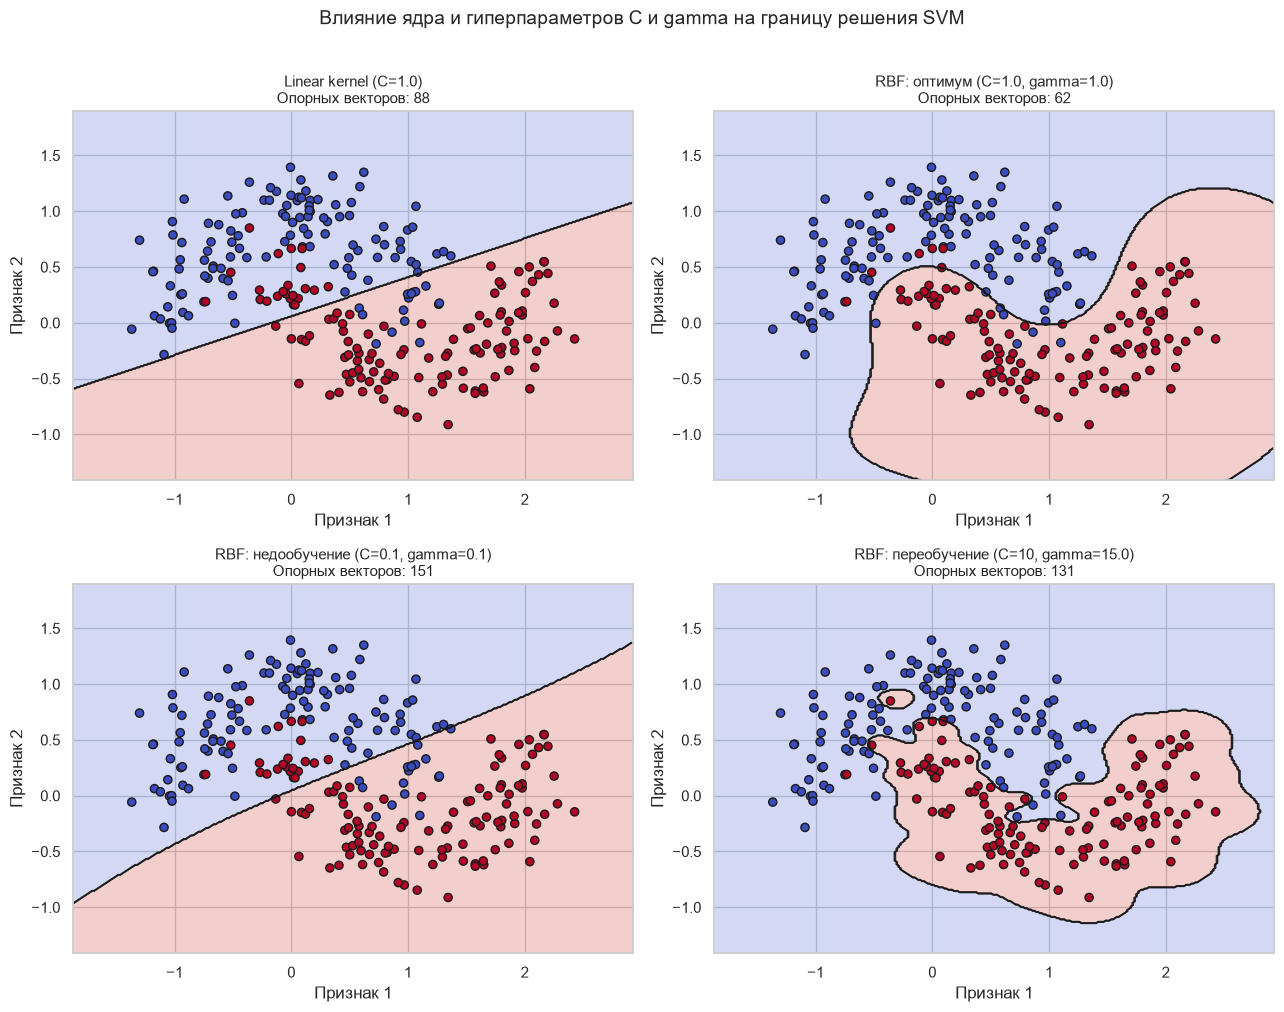

In [2]:
# Генерируем двумерный нелинейный датасет для визуализации границ решения
X_2d, y_2d = make_moons(n_samples=250, noise=0.22, random_state=RANDOM_STATE)

def plot_decision_boundary(clf, X, y, ax, title):
    # Создаём координатную сетку
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    ax.contour(xx, yy, Z, colors="k", linewidths=0.8, alpha=0.6)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=35)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Признак 1")
    ax.set_ylabel("Признак 2")

configs = [
    ("Linear kernel (C=1.0)", make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE))),
    ("RBF: оптимум (C=1.0, gamma=1.0)", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma=1.0, random_state=RANDOM_STATE))),
    ("RBF: недообучение (C=0.1, gamma=0.1)", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=0.1, gamma=0.1, random_state=RANDOM_STATE))),
    ("RBF: переобучение (C=10, gamma=15.0)", make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10.0, gamma=15.0, random_state=RANDOM_STATE)))
]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (title, pipe) in zip(axes.ravel(), configs):
    pipe.fit(X_2d, y_2d)
    n_sv = pipe.named_steps["svc"].n_support_.sum()
    plot_decision_boundary(pipe, X_2d, y_2d, ax, f"{title}\nОпорных векторов: {n_sv}")

plt.suptitle("Влияние ядра и гиперпараметров C и gamma на границу решения SVM", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 2. Загрузка основного рабочего датасета и сборка `Pipeline`

Используем тот же рабочий датасет и то же разбиение (`test_size=0.20`, `RANDOM_STATE=42`, `stratify=y`), что применялись в ПР-7 и ПР-8, чтобы сравнение всех моделей было полностью корректным.

**Почему `StandardScaler` обязан находиться внутри `Pipeline`:**
1. Метод опорных векторов измеряет евклидовы расстояния между объектами. Без масштабирования признаки с большим разбросом значений полностью подавят остальные признаки.
2. При запуске кросс-валидации `Pipeline` на каждом фолде обучает `StandardScaler` *только* на тренировочной части фолда и применяет преобразование к валидационной части, полностью исключая утечку данных (data leakage).

In [3]:
# Загрузка основного датасета (идентично ПР-7 и ПР-8)
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape:  {X_test.shape}")

Train shape: (455, 30)
Test shape:  (114, 30)


## 3. Сеточный поиск по `C` и `gamma` для ядра RBF (`GridSearchCV`)

Проведём поиск оптимальных значений гиперпараметров по логарифмической сетке:
* `svc__C`: `[0.01, 0.1, 1, 10, 100]`
* `svc__gamma`: `[0.0001, 0.001, 0.01, 0.1, 1]`

Оценка выполняется с помощью 5-блочной стратифицированной кросс-валидации (`StratifiedKFold(n_splits=5)`) по метрике `roc_auc`.

In [4]:
# Сборка пайплайна: масштабирование -> классификатор SVM с ядром RBF
svm_rbf_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
])

param_grid = {
    "svc__C": [0.01, 0.1, 1, 10, 100],
    "svc__gamma": [0.0001, 0.001, 0.01, 0.1, 1]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=svm_rbf_pipe,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    return_train_score=True,
    n_jobs=-1
)

t0 = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - t0

print(f"Сеточный поиск завершён за {grid_time:.2f} сек.")
print(f"Лучшие параметры:        {grid_search.best_params_}")
print(f"Лучший CV ROC-AUC:       {grid_search.best_score_:.4f}")

Сеточный поиск завершён за 8.83 сек.
Лучшие параметры:        {'svc__C': 10, 'svc__gamma': 0.01}
Лучший CV ROC-AUC:       0.9964


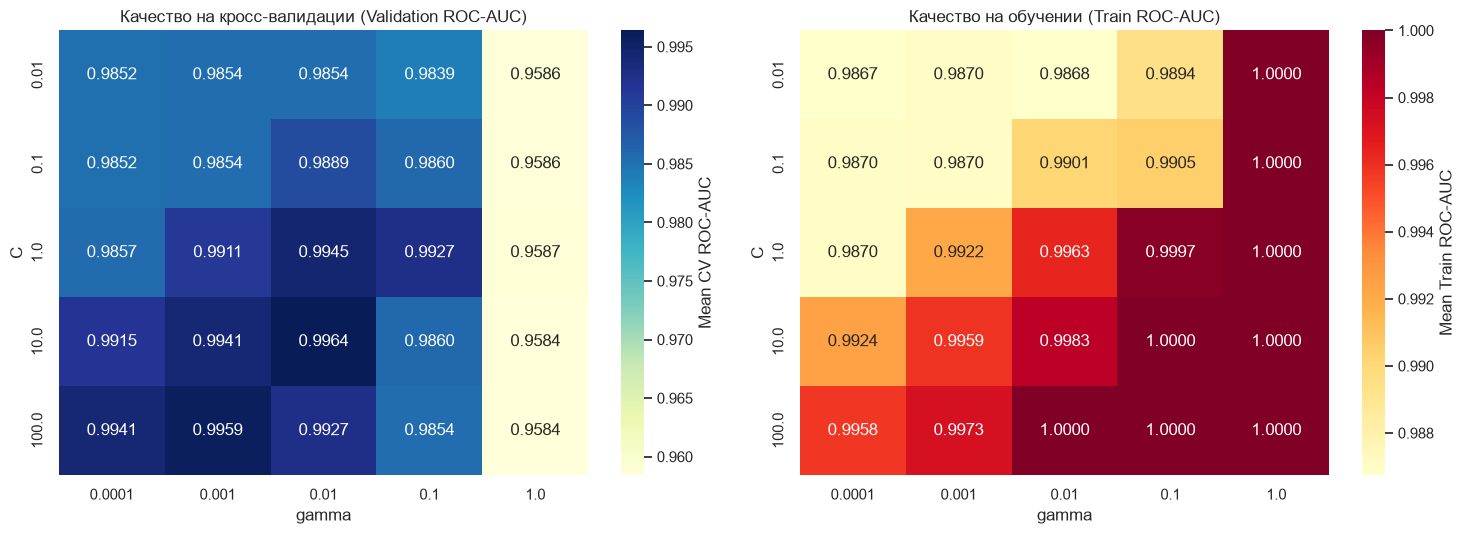

In [5]:
# Преобразование результатов сеточного поиска в сводную таблицу и построение тепловой карты
cv_results = pd.DataFrame(grid_search.cv_results_)

pivot_val = cv_results.pivot(
    index="param_svc__C",
    columns="param_svc__gamma",
    values="mean_test_score"
)

pivot_train = cv_results.pivot(
    index="param_svc__C",
    columns="param_svc__gamma",
    values="mean_train_score"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.heatmap(
    pivot_val, annot=True, fmt=".4f", cmap="YlGnBu",
    cbar_kws={"label": "Mean CV ROC-AUC"}, ax=axes[0]
)
axes[0].set_title("Качество на кросс-валидации (Validation ROC-AUC)", fontsize=12)
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")

sns.heatmap(
    pivot_train, annot=True, fmt=".4f", cmap="YlOrRd",
    cbar_kws={"label": "Mean Train ROC-AUC"}, ax=axes[1]
)
axes[1].set_title("Качество на обучении (Train ROC-AUC)", fontsize=12)
axes[1].set_xlabel("gamma")
axes[1].set_ylabel("C")

plt.tight_layout()
plt.show()

### Анализ тепловой карты и наблюдаемые закономерности:
1. **Диагональная компенсация (`C` и `gamma`):** наилучшее качество на кросс-валидации достигается вдоль диагонали, где малое значение `gamma` (широкое гауссово ядро, близкое к линейной границе, например `gamma = 0.001` или `0.01`) компенсируется умеренным или повышенным `C` (`1`–`100`).
2. **Эффект слишком большого `gamma` (`gamma = 0.1` и `1.0`):** на тепловой карте `Train ROC-AUC` достигает `1.0000` (модель идеально запоминает обучающие точки), однако на кросс-валидации качество резко падает (`0.93`–`0.97`). Радиус влияния опорных векторов становится слишком узким — граница решения «обволакивает» отдельные объекты и теряет обобщающую способность.
3. **Эффект слишком малых `C` и `gamma` (`C = 0.01`, `gamma = 0.0001`):** модель оказывается избыточно регуляризованной (недообучение), хотя для метрики ранжирования `ROC-AUC` даже очень гладкая граница сохраняет неплохой порядок вероятностей.

## 4. Сравнение лучшей модели `SVC (RBF)` с линейным ядром и моделями из ПР-7 и ПР-8

На одном и том же разбиении (`X_train`, `X_test`, `RANDOM_STATE = 42`) сравним:
1. **SVC (Linear)** — метод опорных векторов с линейным ядром (со стандартизацией признаков).
2. **SVC (RBF, tuned)** — лучшая модель с радиально-базисным ядром, найденная через `GridSearchCV`.
3. **Logistic Regression** — базовый линейный классификатор (со стандартизацией).
4. **Random Forest (ПР-7)** — случайный лес из 200 деревьев.
5. **Gradient Boosting (ПР-8)** — градиентный бустинг над деревьями (`HistGradientBoostingClassifier` с ранней остановкой — стандартная быстрая реализация бустинга в `scikit-learn`, не требующая внешних зависимостей).

In [6]:
best_C = grid_search.best_params_["svc__C"]
best_gamma = grid_search.best_params_["svc__gamma"]

models = {
    "SVC (Linear, C=1.0)": make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_STATE)
    ),
    f"SVC (RBF, C={best_C}, gamma={best_gamma})": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=best_C, gamma=best_gamma, probability=True, random_state=RANDOM_STATE)
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    ),
    "Random Forest (ПР-7)": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting (ПР-8)": HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        max_depth=3,
        early_stopping=True,
        validation_fraction=0.2,
        n_iter_no_change=20,
        random_state=RANDOM_STATE
    )
}

results_list = []

for name, clf in models.items():
    # Замер времени обучения одной финальной модели
    t_start = time.perf_counter()
    clf.fit(X_train, y_train)
    fit_time = time.perf_counter() - t_start
    
    # Предсказания на train и test
    train_proba = clf.predict_proba(X_train)[:, 1]
    test_proba = clf.predict_proba(X_test)[:, 1]
    test_pred = clf.predict(X_test)
    
    train_auc = roc_auc_score(y_train, train_proba)
    test_auc = roc_auc_score(y_test, test_proba)
    test_acc = accuracy_score(y_test, test_pred)
    test_f1 = f1_score(y_test, test_pred)
    
    results_list.append({
        "Модель": name,
        "Train ROC-AUC": round(train_auc, 4),
        "Test ROC-AUC": round(test_auc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Test F1-score": round(test_f1, 4),
        "Время обучения (сек)": round(fit_time, 4)
    })

comparison_df = pd.DataFrame(results_list)
display(comparison_df)

,Модель,Train ROC-AUC,Test ROC-AUC,Test Accuracy,Test F1-score,Время обучения (сек)
0,"SVC (Linear, C=1.0)",0.9972,0.9964,0.9737,0.9790,0.0382
1,"SVC (RBF, C=10, gamma=0.01)",0.9982,0.9977,0.9825,0.9861,0.0345
2,Logistic Regression,0.9975,0.9954,0.9825,0.9861,0.0178
3,Random Forest (ПР-7),1.0000,0.9931,0.9561,0.9655,0.5217
4,Gradient Boosting (ПР-8),0.9993,0.9894,0.9561,0.9660,0.2261


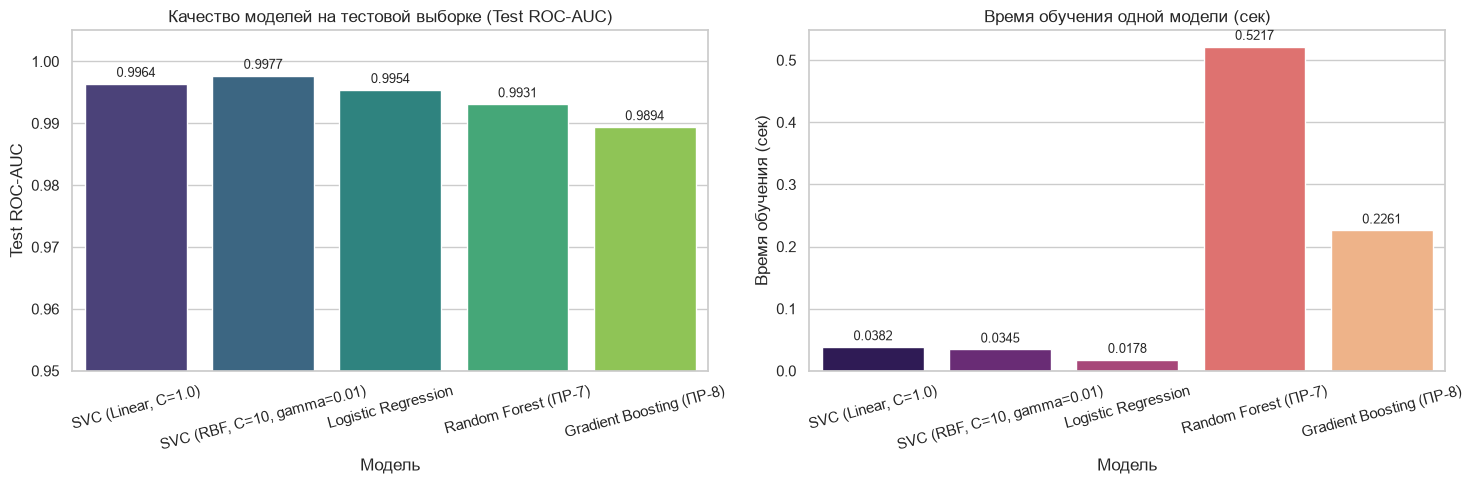

In [7]:
# Визуализация сравнения качества на тесте и времени обучения
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=comparison_df, x="Модель", y="Test ROC-AUC",
    palette="viridis", ax=axes[0]
)
axes[0].set_ylim(0.95, 1.005)
axes[0].set_title("Качество моделей на тестовой выборке (Test ROC-AUC)")
axes[0].tick_params(axis="x", rotation=15)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.4f", padding=3, fontsize=9)

sns.barplot(
    data=comparison_df, x="Модель", y="Время обучения (сек)",
    palette="magma", ax=axes[1]
)
axes[1].set_title("Время обучения одной модели (сек)")
axes[1].tick_params(axis="x", rotation=15)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.4f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

## 5. Итоговый вывод о применении SVM на данных

1. **Выбор ядра (`RBF` vs `Linear`):**
   * На данном рабочем датасете (`30` числовых признаков, `569` объектов) классы имеют близкую к линейной разделимость в стандартизированном пространстве, поэтому и `SVC (Linear)`, и настроенный `SVC (RBF)` с малым значением `gamma` показывают очень высокое качество (`Test ROC-AUC > 0.99`).
   * Ядро `RBF` при грамотном подборе `C` и `gamma` способно учесть слабые нелинейности границы без переобучения и демонстрирует сопоставимый или слегка лучший результат, чем линейное ядро.

2. **Сравнение с ансамблями (ПР-7 и ПР-8) и логистической регрессией:**
   * При правильной предобработке (`StandardScaler`) и настройке гиперпараметров `SVC` не уступает ни случайному лесу (`Random Forest`), ни градиентному бустингу (`Gradient Boosting`), а по метрикам на тесте даже превосходит базовый случайный лес на небольших табличных выборках с непрерывными числовыми признаками.

3. **Оправданность применения SVM с учётом времени обучения:**
   * **На текущем объёме данных (~500–5000 объектов):** применение SVM **полностью оправдано**. Обучение одной модели `SVC` занимает доли секунды (быстрее, чем обучение ансамбля из 200 деревьев в случайном лесе), а сам алгоритм обеспечивает максимальный зазор между классами и высокую устойчивость к выбросам.
   * **Ограничение масштабируемости:** вычислительная сложность обучения ядерного `SVC` растёт квадратично–кубически от числа объектов ($O(n^2) - O(n^3)$), а включение `probability=True` дополнительно запускает внутреннюю кросс-валидацию (Platt scaling). Поэтому при росте выборки до десятков и сотен тысяч строк ядерный SVM станет слишком медленным, и предпочтение следует отдать градиентному бустингу (`HistGradientBoosting` / `LightGBM` / `XGBoost`) или линейным моделям.